# SegFormer-B0 (ADE20K pretrained)

This notebook fine-tunes SegFormer-B0, a transformer model for semantic segmentation (Xie et al., 2021). It has a hierarchical transformer encoder and a small MLP decoder. B0 is the smallest version with 3.7M parameters, which is about the same size as SUIM-Net RSB.

Our first SegFormer notebook (03) starts from the ImageNet encoder only and trains 5 sigmoid outputs with BCE. This notebook tests whether a different setup works better on SUIM:

- it starts from a full SegFormer that was already trained for segmentation on ADE20K
- it trains on all 8 SUIM classes, with one class per pixel
- it uses cross-entropy + Dice as the loss

The data loading, split and evaluation are the same as in the MobileNetV2 notebook (09). For the evaluation, the robot, fish, diver, reef and wreck pixels are taken from the 8-class prediction.

This notebook uses PyTorch and Hugging Face `transformers` and it was run on the Colabs T4 GPU.

## Connect to Drive

`SUIM_RSB_data.zip` has to be in My Drive (still zipped). This cell connects Drive.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Imports

This cell also prints the PyTorch version and checks that a GPU is available.

In [ ]:
import hashlib, json, random, time, zipfile
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import binary_dilation
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import SegformerForSemanticSegmentation

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| device:', device)

torch 2.14.1+cu130 | device: cuda


## Settings

`QUICK_TEST = True` trains for 2 epochs on a few images to check that everything works. The results below are from the full run with `QUICK_TEST = False`. Each run is saved to a new folder in My Drive / SUIM_runs.

In [ ]:
DATA_ZIP = Path('/content/drive/MyDrive/SUIM_RSB_data.zip')
DATA_DIR = Path('/content/suim_data')  # local copy, faster than reading from Drive
RUNS_DIR = Path('/content/drive/MyDrive/SUIM_runs')

QUICK_TEST = False  # True = short test run

MODEL_NAME = 'nvidia/segformer-b0-finetuned-ade-512-512'  # pretrained on ADE20K
IMG_H, IMG_W = 256, 320    # has to be divisible by 32
EVAL_W, EVAL_H = 320, 240  # evaluation size from the SUIM paper
BATCH_SIZE = 8
EPOCHS = 50
LR = 6e-5                  # from the SegFormer paper
WEIGHT_DECAY = 0.01
PATIENCE = 10              # epochs without improvement before stopping
SEED = 42

# all 8 SUIM classes for training (the list index is the class id)
LABELS = ['Water', 'Divers', 'Plants', 'Wrecks', 'Robots', 'Reefs', 'Fish', 'Sea-floor']
NUM_CLASSES = len(LABELS)
# the 5 classes from the paper, used for the evaluation
CLASS_IDS = {'RO': 4, 'FV': 6, 'HD': 1, 'RI': 5, 'WR': 3}
CLASSES = list(CLASS_IDS)
MODEL_LABEL = 'SegFormer-B0 (ADE20K)'

if QUICK_TEST:
    EPOCHS = 2
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
USE_AMP = device.type == 'cuda'  # mixed precision, faster on the T4
RUN_DIR = RUNS_DIR / ('10_segformer_b0_ade20k_' + datetime.now().strftime('%Y%m%d_%H%M') + ('_quicktest' if QUICK_TEST else ''))
RUN_DIR.mkdir(parents=True, exist_ok=True)
print('Saving results to', RUN_DIR)

Saving results to /content/drive/MyDrive/SUIM_runs/10_segformer_b0_ade20k_20261116_1935


## Unzip the dataset

(the data is first unzipped to Colab's local storage.)

In [ ]:
if not (DATA_DIR / 'done.txt').exists():
    print('Unzipping', DATA_ZIP.name, '...')
    with zipfile.ZipFile(DATA_ZIP) as z:
        z.extractall(DATA_DIR)
    (DATA_DIR / 'done.txt').write_text('ok')

def find_split(name):
    # works with the cleaned zip or the original SUIM folders
    found = [p for p in DATA_DIR.rglob(name) if (p / 'images').is_dir() and '__MACOSX' not in str(p)]
    found.sort(key=lambda p: 'cleaned' not in str(p))  # use the cleaned copy if both exist
    if not found:
        raise FileNotFoundError(f'No {name}/images folder inside {DATA_ZIP.name}')
    return found[0]

TRAIN_DIR, TEST_DIR = find_split('train_val'), find_split('TEST')
print('Train:', TRAIN_DIR)
print('Test: ', TEST_DIR)

Unzipping SUIM_RSB_data.zip ...
Train: /content/suim_data/cleaned_suim/train_val
Test:  /content/suim_data/TEST


## Prepare the data and split it

The images are matched with their masks by filename and resized to 320x256. Each mask is stored as one class id per pixel. The split is 80/20 with seed 42, which gives the same train/val images as our other notebooks.

This cell also finds the TEST images that are exact copies of training images (there are 4), so they can be left out later.

In [ ]:
IMG_EXTS, MASK_EXTS = {'.jpg', '.jpeg', '.png'}, {'.bmp', '.png'}

def index_files(folder, exts):
    return {p.stem: p for p in sorted(Path(folder).iterdir()) if p.suffix.lower() in exts}

def mask_to_ids(mask):
    # values above 127.5 count as 1, so slightly off colors like (255, 0, 254) still work
    bits = (np.asarray(mask) > 127.5).astype(np.uint8)
    # class ids: 0 BW, 1 HD, 2 PF, 3 WR, 4 RO, 5 RI, 6 FV, 7 SR
    return 4 * bits[..., 0] + 2 * bits[..., 1] + bits[..., 2]

def load_pair(img_path, mask_path):
    img = Image.open(img_path).convert('RGB')
    mask = Image.open(mask_path).convert('RGB')
    cropped = False
    if mask.size != img.size:
        # some masks are taller than their image, crop the extra rows at the bottom
        if mask.width == img.width and mask.height > img.height:
            mask, cropped = mask.crop((0, 0, img.width, img.height)), True
        else:
            raise ValueError(f'{img_path.stem}: image {img.size} vs mask {mask.size}')
    img = np.asarray(img.resize((IMG_W, IMG_H), Image.BILINEAR))
    ids = mask_to_ids(mask.resize((IMG_W, IMG_H), Image.NEAREST))
    return img, ids, cropped

def file_sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def grouped_split(images, val_fraction=0.2, seed=SEED):
    # identical images stay in the same split
    groups = {}
    for stem, path in images.items():
        groups.setdefault(file_sha256(path), []).append(stem)
    hashes = np.array(sorted(groups))
    np.random.default_rng(seed).shuffle(hashes)
    val_hashes = set(hashes[:round(len(hashes) * val_fraction)])
    train = sorted(s for h in hashes if h not in val_hashes for s in groups[h])
    val = sorted(s for h in val_hashes for s in groups[h])
    return train, val

train_images = index_files(TRAIN_DIR / 'images', IMG_EXTS)
train_masks = index_files(TRAIN_DIR / 'masks', MASK_EXTS)
assert train_images.keys() == train_masks.keys(), 'every training image needs a mask with the same name'
train_stems, val_stems = grouped_split(train_images)

test_images = index_files(TEST_DIR / 'images', IMG_EXTS)
gt_masks = {c: index_files(TEST_DIR / 'masks' / c, MASK_EXTS) for c in CLASSES}
test_stems = sorted(test_images)

# find the TEST images that are exact copies of training images
train_hashes = {file_sha256(p) for p in train_images.values()}
overlap_stems = sorted(s for s, p in test_images.items() if file_sha256(p) in train_hashes)

if QUICK_TEST:
    train_stems, val_stems, test_stems = train_stems[:16], val_stems[:8], test_stems[:6]

def load_set(stems):
    X = np.zeros((len(stems), IMG_H, IMG_W, 3), np.uint8)
    Y = np.zeros((len(stems), IMG_H, IMG_W), np.uint8)  # class ids 0-7
    n_cropped = 0
    for i, s in enumerate(stems):
        X[i], Y[i], cropped = load_pair(train_images[s], train_masks[s])
        n_cropped += cropped
    return X, Y, n_cropped

t0 = time.time()
X_train, Y_train, c1 = load_set(train_stems)
X_val, Y_val, c2 = load_set(val_stems)
print(f'{len(train_stems)} train / {len(val_stems)} val / {len(test_stems)} test images')
print(f'TEST images that also appear in training: {overlap_stems}')
print(f'Cropped {c1 + c2} tall masks (0 if the data is already cleaned)')
print(f'Loading took {time.time() - t0:.0f}s')

1220 train / 305 val / 110 test images
TEST images that also appear in training: ['d_r_386_', 'n_l_0_', 'n_l_29_', 'n_l_87_']
Cropped 0 tall masks (0 if the data is already cleaned)
Loading took 20s


## Build the datasets

The augmentation is the same as in the MobileNetV2 notebook: each image and its mask are flipped together at random and the brightness and contrast are changed slightly. The images are normalized with the ImageNet mean and standard deviation, since SegFormer was pretrained that way.

In [ ]:
MEAN = np.array([0.485, 0.456, 0.406], np.float32)
STD = np.array([0.229, 0.224, 0.225], np.float32)

def normalize(img):
    img = (img - MEAN) / STD
    return torch.from_numpy(np.ascontiguousarray(img.transpose(2, 0, 1))).float()

class SUIMDataset(torch.utils.data.Dataset):
    def __init__(self, X, Y, augment=False):
        self.X, self.Y, self.augment = X, Y, augment

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        img, ids = self.X[i].astype(np.float32) / 255.0, self.Y[i]
        if self.augment:
            if random.random() < 0.5:
                img, ids = img[:, ::-1], ids[:, ::-1]
            img = img + random.uniform(-0.08, 0.08)                     # brightness
            mean = img.mean(axis=(0, 1))
            img = (img - mean) * random.uniform(0.9, 1.1) + mean       # contrast
            img = np.clip(img, 0, 1)
        return normalize(img), torch.from_numpy(np.ascontiguousarray(ids)).long()

train_set = SUIMDataset(X_train, Y_train, augment=True)
val_set = SUIMDataset(X_val, Y_val)
train_loader = torch.utils.data.DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
                                           num_workers=2, pin_memory=True)
val_loader = torch.utils.data.DataLoader(val_set, batch_size=BATCH_SIZE, num_workers=2)

## Build the model

SegFormer-B0 is loaded with a new 8-class head. The pretrained head has 150 classes (ADE20K), so `ignore_mismatched_sizes` is needed and the load report below shows the classifier being re-initialized. SegFormer outputs its logits at 1/4 of the input size, so they are upsampled before the loss.

The loss is cross-entropy + Dice. The optimizer is AdamW with a cosine learning rate schedule, starting at 6e-5 as in the SegFormer paper.

In [ ]:
id2label = dict(enumerate(LABELS))
model = SegformerForSemanticSegmentation.from_pretrained(
    MODEL_NAME, num_labels=NUM_CLASSES, id2label=id2label,
    label2id={v: k for k, v in id2label.items()}, ignore_mismatched_sizes=True)
model.to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f'params: {n_params:,}')

ce = nn.CrossEntropyLoss()

def loss_fn(logits, y):
    probs = logits.softmax(1)
    onehot = F.one_hot(y, NUM_CLASSES).permute(0, 3, 1, 2).float()
    inter = (probs * onehot).sum((0, 2, 3))
    denom = probs.sum((0, 2, 3)) + onehot.sum((0, 2, 3))
    dice = (2 * inter + 1) / (denom + 1)
    return ce(logits, y) + (1 - dice.mean())

def upsample(logits, size):
    return F.interpolate(logits, size=size, mode='bilinear', align_corners=False)

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler = torch.amp.GradScaler(device.type, enabled=USE_AMP)

config.json:   0%|          | 0.00/6.88k [00:00<?, ?B/s]

[transformers] You passed `num_labels=8` which is incompatible to the `id2label` map of length `150`.


model.safetensors: reconstructing file:   0%|          |  0.00B / 15.0MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b0-finetuned-ade-512-512
Key                           | Status   |                                                                                                     
------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([8, 256, 1, 1])
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([8])                      

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


params: 3,716,200


## Train the model

After each epoch, the 8-class mIoU is computed on the validation set and the model is saved if it improved. Training stops when the mIoU has not improved for 10 epochs.

epoch   1 | loss 2.1727 | val loss 1.7033 | val mIoU 0.2934
epoch   2 | loss 1.5927 | val loss 1.4246 | val mIoU 0.3797
epoch   3 | loss 1.3639 | val loss 1.3579 | val mIoU 0.3905
epoch   4 | loss 1.2331 | val loss 1.3109 | val mIoU 0.4457
epoch   5 | loss 1.1427 | val loss 1.2364 | val mIoU 0.4725
epoch   6 | loss 1.0600 | val loss 1.2097 | val mIoU 0.4827
epoch   7 | loss 1.0022 | val loss 1.1939 | val mIoU 0.4895
epoch   8 | loss 0.9458 | val loss 1.1692 | val mIoU 0.4999
epoch   9 | loss 0.9169 | val loss 1.1773 | val mIoU 0.5035
epoch  10 | loss 0.8694 | val loss 1.1430 | val mIoU 0.5272
epoch  11 | loss 0.8151 | val loss 1.1829 | val mIoU 0.5462
epoch  12 | loss 0.7920 | val loss 1.1564 | val mIoU 0.5829
epoch  13 | loss 0.7680 | val loss 1.1828 | val mIoU 0.5942
epoch  14 | loss 0.7298 | val loss 1.2014 | val mIoU 0.5885
epoch  15 | loss 0.7149 | val loss 1.1681 | val mIoU 0.6101
epoch  16 | loss 0.7045 | val loss 1.1517 | val mIoU 0.6158
epoch  17 | loss 0.6721 | val loss 1.170

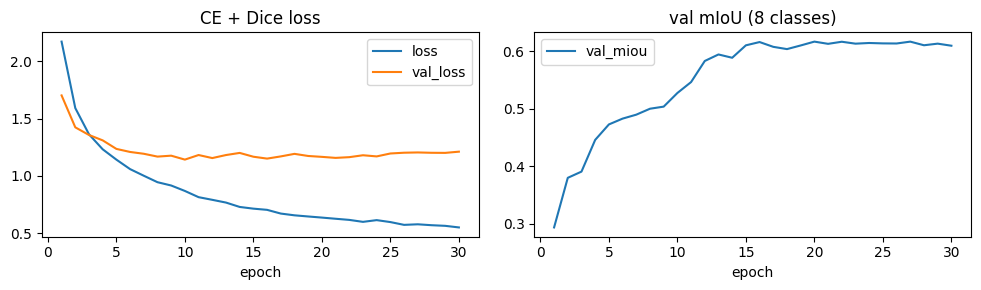

In [ ]:
@torch.no_grad()
def validate():
    model.eval()
    conf = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long, device=device)
    total_loss = 0.0
    for x, y in val_loader:
        x, y = x.to(device), y.to(device)
        with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(pixel_values=x).logits
        logits = upsample(logits.float(), y.shape[-2:])
        total_loss += loss_fn(logits, y).item() * len(x)
        pred = logits.argmax(1)
        conf += torch.bincount(y.flatten() * NUM_CLASSES + pred.flatten(),
                               minlength=NUM_CLASSES ** 2).view(NUM_CLASSES, NUM_CLASSES)
    union = conf.sum(0) + conf.sum(1) - conf.diag()
    iou = (conf.diag().float() / union.clamp(min=1)).cpu().numpy()
    present = (conf.sum(1) > 0).cpu().numpy()  # only average the classes that are in the validation set
    return total_loss / len(val_set), iou, float(iou[present].mean())

best_path = RUN_DIR / 'best_segformer.pt'
history, best_miou, bad_epochs = [], -1.0, 0
t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train()
    running = 0.0
    for x, y in train_loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(pixel_values=x).logits
        loss = loss_fn(upsample(logits.float(), y.shape[-2:]), y)
        optimizer.zero_grad()
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running += loss.item() * len(x)
    scheduler.step()

    val_loss, val_iou, val_miou = validate()
    history.append({'epoch': epoch, 'loss': running / (len(train_loader) * BATCH_SIZE),
                    'val_loss': val_loss, 'val_miou': val_miou})
    print(f"epoch {epoch:3d} | loss {history[-1]['loss']:.4f} | val loss {val_loss:.4f} | val mIoU {val_miou:.4f}")

    if val_miou > best_miou:
        best_miou, bad_epochs = val_miou, 0
        torch.save(model.state_dict(), best_path)
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print(f'early stopping, no improvement for {PATIENCE} epochs')
            break
train_minutes = (time.time() - t0) / 60

model.load_state_dict(torch.load(best_path, map_location=device))
hist = pd.DataFrame(history)
hist.to_csv(RUN_DIR / 'history.csv', index=False)
print(f'trained {len(hist)} epochs in {train_minutes:.1f} min, best val mIoU {best_miou:.4f}')

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
hist.plot(x='epoch', y=['loss', 'val_loss'], ax=ax[0], title='CE + Dice loss')
hist.plot(x='epoch', y='val_miou', ax=ax[1], title='val mIoU (8 classes)')
plt.tight_layout()
plt.savefig(RUN_DIR / 'training_curves.png', dpi=120)
plt.show()

**Training:**

- Training stopped early after 30 epochs, which only took 8.2 min on the T4. The best validation mIoU was **0.6166** at epoch 20.
- The validation loss stops improving after about epoch 10 and stays around 1.15 to 1.2, while the training loss keeps going down, so this model overfits as well.
- The mIoU still improved until around epoch 16, even though the validation loss did not.

## Check all 8 classes

The paper only reports 5 classes, but this model predicts all 8, so this table shows the IoU of each class on the validation set.

In [ ]:
_, val_iou, val_miou = validate()
val_table = pd.DataFrame({'class': LABELS, 'val_iou_pct': (100 * val_iou).round(2)})
val_table.to_csv(RUN_DIR / 'val_iou_8class.csv', index=False)
display(val_table)
print(f'val mIoU (8 classes): {100 * val_miou:.2f}%')

,class,val_iou_pct
0,Water,83.839996
1,Divers,67.750000
2,Plants,11.340000
3,Wrecks,72.570000
4,Robots,64.320000
5,Reefs,73.379997
6,Fish,66.930000
7,Sea-floor,53.110001


val mIoU (8 classes): 61.66%


- The 8-class validation mIoU is **61.66%**.
- Water is the easiest class (83.84) and plants are by far the worst (11.34).
- The number of pixels alone does not explain this, since robots have even fewer pixels and still reach 64.32. A likely reason is that plants are confused with reefs and the sea-floor (but we did not check this).

## Predict on the test images

For each pixel, the class with the highest score is taken and one mask is saved for each of the 5 evaluation classes.

The cell also prints an FPS number (70.1 on the T4). Our other models were timed on a different GPU, so it cannot be compared with them directly.

In [ ]:
PRED_DIR = RUN_DIR / 'predictions'
for c in CLASSES:
    (PRED_DIR / c).mkdir(parents=True, exist_ok=True)

model.eval()
times = []
with torch.no_grad():
    for i, stem in enumerate(test_stems):
        img = Image.open(test_images[stem]).convert('RGB').resize((IMG_W, IMG_H), Image.BILINEAR)
        x = normalize(np.asarray(img, np.float32) / 255.0)[None].to(device)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        logits = upsample(model(pixel_values=x).logits, (IMG_H, IMG_W))
        ids = logits.argmax(1)[0].cpu().numpy()
        if i > 0:  # skip the first image (warm-up)
            times.append(time.perf_counter() - t0)
        for c, k in CLASS_IDS.items():
            Image.fromarray(((ids == k) * 255).astype(np.uint8)).save(PRED_DIR / c / f'{stem}.bmp')

fps = 1 / np.mean(times) if times else float('nan')
print(f'saved predictions for {len(test_stems)} test images')
print(f'params: {n_params:,} | inference: {fps:.1f} FPS (batch 1, {IMG_W}x{IMG_H})')

saved predictions for 110 test images
params: 3,716,200 | inference: 70.1 FPS (batch 1, 320x256)


## Evaluate on the test images

This is the same evaluation as in the SUIM paper: boundary F-score and IoU at 320x240. A class is only scored on the images where it appears in the ground truth and the final score is the average of the 5 class scores. The pixel Dice and the boundary precision/recall are saved as well.

Four of the TEST images are exact copies of training images, so the scores are also shown without them (106 images).

In [ ]:
# evaluation functions from the original SUIM code
def disk(radius):
    y, x = np.ogrid[-radius:radius + 1, -radius:radius + 1]
    return x * x + y * y <= radius * radius

def seg2bmap(seg):
    seg = np.asarray(seg, dtype=bool)
    e, s, se = np.zeros_like(seg), np.zeros_like(seg), np.zeros_like(seg)
    e[:, :-1] = seg[:, 1:]
    s[:-1, :] = seg[1:, :]
    se[:-1, :-1] = seg[1:, 1:]
    boundary = seg ^ e | seg ^ s | seg ^ se
    boundary[-1, :] = seg[-1, :] ^ e[-1, :]
    boundary[:, -1] = seg[:, -1] ^ s[:, -1]
    boundary[-1, -1] = False
    return boundary

def db_eval_boundary(foreground_mask, gt_mask, bound_th=0.008):
    bound_pix = bound_th if bound_th >= 1 else np.ceil(bound_th * np.linalg.norm(foreground_mask.shape))
    fg_boundary = seg2bmap(foreground_mask)
    gt_boundary = seg2bmap(gt_mask)
    fg_dil = binary_dilation(fg_boundary, disk(int(bound_pix)))
    gt_dil = binary_dilation(gt_boundary, disk(int(bound_pix)))
    gt_match = gt_boundary * fg_dil
    fg_match = fg_boundary * gt_dil
    n_fg, n_gt = np.sum(fg_boundary), np.sum(gt_boundary)
    if n_fg == 0 and n_gt > 0:
        precision, recall = 1, 0
    elif n_fg > 0 and n_gt == 0:
        precision, recall = 0, 1
    elif n_fg == 0 and n_gt == 0:
        precision, recall = 1, 1
    else:
        precision = np.sum(fg_match) / float(n_fg)
        recall = np.sum(gt_match) / float(n_gt)
    F = 0 if precision + recall == 0 else 2 * precision * recall / (precision + recall)
    return precision, recall, F

def IoU_bin(target, prediction):
    union = np.logical_or(target, prediction).sum()
    return float(np.logical_and(target, prediction).sum() / union) if union else 1.0

def read_and_bin(path, size):
    with Image.open(path) as source:
        image = source.convert('L').resize(size, Image.BICUBIC)
    return np.asarray(image, dtype=np.float32) / 255.0 >= 0.5

def evaluate(pred_dir, stems):
    rows = []
    for c in CLASSES:
        for stem in stems:
            gt = read_and_bin(gt_masks[c][stem], (EVAL_W, EVAL_H))
            pred = read_and_bin(pred_dir / c / f'{stem}.bmp', (EVAL_W, EVAL_H))
            # only score a class on images where it's in the ground truth
            if not gt.any():
                continue
            p, r, f = db_eval_boundary(pred, gt)
            dice = 2 * (gt & pred).sum() / (gt.sum() + pred.sum())
            rows.append({'stem': stem, 'class': c, 'boundary_f': f, 'iou': IoU_bin(gt, pred),
                         'pixel_dice': dice, 'boundary_precision': p, 'boundary_recall': r})
    per_image = pd.DataFrame(rows)
    return per_image, summarize(per_image)

def summarize(per_image):
    metrics = ['boundary_f', 'iou', 'pixel_dice', 'boundary_precision', 'boundary_recall']
    per_class = per_image.groupby('class', sort=False)[metrics].mean().mul(100).round(2)
    per_class.insert(0, 'images', per_image.groupby('class', sort=False).size())
    return per_class

In [ ]:
per_image, per_class = evaluate(PRED_DIR, test_stems)
per_class_no_overlap = summarize(per_image[~per_image.stem.isin(overlap_stems)])
per_image.to_csv(RUN_DIR / 'per_image_metrics.csv', index=False)
per_class.to_csv(RUN_DIR / 'class_metrics.csv')
per_class_no_overlap.to_csv(RUN_DIR / 'class_metrics_no_overlap.csv')
n_no_overlap = len(set(test_stems) - set(overlap_stems))

print(f'All {len(test_stems)} test images')
display(per_class)
print(f'Without the overlapping images ({n_no_overlap} test images)')
display(per_class_no_overlap)

summary = {
    'model': MODEL_LABEL, 'notebook': '10_segformer_b0_ade20k', 'pretrained': MODEL_NAME, 'quick_test': QUICK_TEST,
    'input_size_wh': [IMG_W, IMG_H], 'eval_size_wh': [EVAL_W, EVAL_H],
    'train_images': len(train_stems), 'val_images': len(val_stems), 'test_images': len(test_stems),
    'epochs_trained': len(hist), 'train_minutes': round(train_minutes, 1),
    'params': int(n_params), 'fps': round(float(fps), 1),
    'macro_boundary_f': round(float(per_class.boundary_f.mean()), 2),
    'macro_iou': round(float(per_class.iou.mean()), 2),
    'macro_pixel_dice': round(float(per_class.pixel_dice.mean()), 2),
    'test_images_no_overlap': n_no_overlap, 'overlap_stems': overlap_stems,
    'macro_boundary_f_no_overlap': round(float(per_class_no_overlap.boundary_f.mean()), 2),
    'macro_iou_no_overlap': round(float(per_class_no_overlap.iou.mean()), 2),
    'val_miou_8class': round(100 * val_miou, 2),
}
(RUN_DIR / 'summary.json').write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

All 110 test images


,images,boundary_f,iou,pixel_dice,boundary_precision,boundary_recall
class,,,,,,
RO,12,51.43,48.81,58.47,74.91,51.47
FV,66,56.75,56.00,65.12,75.17,51.04
HD,42,64.20,60.47,69.18,80.79,60.89
RI,58,39.28,62.22,69.66,55.01,35.00
WR,27,51.18,65.90,72.69,68.01,46.41


Without the overlapping images (106 test images)


,images,boundary_f,iou,pixel_dice,boundary_precision,boundary_recall
class,,,,,,
RO,10,54.15,52.47,62.59,72.12,54.39
FV,65,56.46,55.98,65.00,74.83,50.88
HD,39,62.97,59.17,67.80,80.10,60.00
RI,56,38.56,62.44,69.84,54.25,34.49
WR,26,52.25,66.11,72.59,69.86,47.13


{
  "model": "SegFormer-B0 (ADE20K)",
  "notebook": "10_segformer_b0_ade20k",
  "pretrained": "nvidia/segformer-b0-finetuned-ade-512-512",
  "quick_test": false,
  "input_size_wh": [
    320,
    256
  ],
  "eval_size_wh": [
    320,
    240
  ],
  "train_images": 1220,
  "val_images": 305,
  "test_images": 110,
  "epochs_trained": 30,
  "train_minutes": 8.2,
  "params": 3716200,
  "fps": 70.1,
  "macro_boundary_f": 52.57,
  "macro_iou": 58.68,
  "macro_pixel_dice": 67.02,
  "test_images_no_overlap": 106,
  "overlap_stems": [
    "d_r_386_",
    "n_l_0_",
    "n_l_29_",
    "n_l_87_"
  ],
  "macro_boundary_f_no_overlap": 52.88,
  "macro_iou_no_overlap": 59.23,
  "val_miou_8class": 61.66
}


**Results** (all 110 test images):

| Model | Notebook | Params | Boundary F | IoU |
|---|---|---|---|---|
| U-Net (paper's weights) | 02 | 31.0M | 82.95 | 80.03 |
| SUIM-Net RSB (paper's weights) | 08 | 3.9M | 74.80 | 76.67 |
| MobileNetV2 U-Net | 09 | 5.4M | **59.07** | **62.54** |
| SegFormer-B0, ADE20K | this one | 3.7M | 52.57 | 58.68 |
| UNetFormer ResNet18 | 04 | 11.7M | 51.77 | 56.16 |
| U-Net ResNet18 | 05 | 14.3M | 51.53 | 57.40 |
| SegFormer-B0, ImageNet encoder | 03 | 3.7M | 46.15 | 52.22 |

The first two rows use the weights from the paper's authors. The other models were trained by us, each with a single run.

- This setup reaches **52.57** boundary F and **58.68** IoU, which is **+6.42** F and **+6.46** IoU higher than our first SegFormer (03).
- Several things were changed at once (ADE20K pretraining, the Dice loss, 8 classes, batch size 8 instead of 2, different augmentation), so we cannot say which one helped the most.
- It is still below the MobileNetV2 U-Net (-6.50 F, -3.86 IoU), so the transformer did not beat the CNN in our experiments. It is the smallest model we trained and it trained in only 8 minutes instead of 44.
- Wrecks are the only class where SegFormer is better than the MobileNetV2 U-Net (65.90 vs 58.82 IoU). Its worst class is reefs with 39.28 boundary F.
- Without the 4 copied images the scores are 52.88 F and 59.23 IoU, which is slightly higher, as with our other models.
- All of the models we trained are still well below the paper's pretrained models.

## Show example predictions

The first 4 test images with their ground truth and the prediction. The colors follow the SUIM labels: red = robots, yellow = fish, blue = divers, magenta = reefs, cyan = wrecks and black = background.

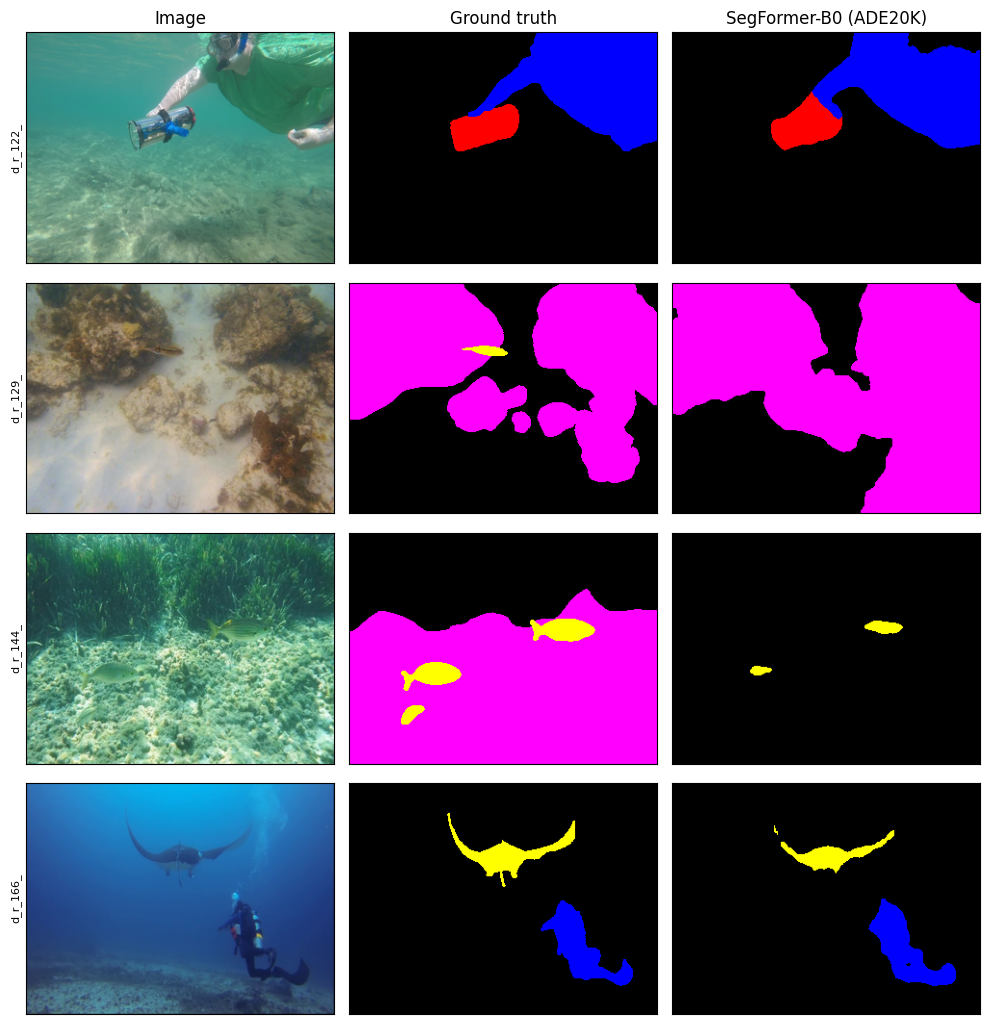

In [ ]:
COLORS = {'RO': (255, 0, 0), 'FV': (255, 255, 0), 'HD': (0, 0, 255), 'RI': (255, 0, 255), 'WR': (0, 255, 255)}

def color_mask(paths):
    out = np.zeros((EVAL_H, EVAL_W, 3), np.uint8)
    for c, path in paths.items():
        out[read_and_bin(path, (EVAL_W, EVAL_H))] = COLORS[c]
    return out

examples = test_stems[:4]  # same images for every model so the figures can be compared
fig, axes = plt.subplots(len(examples), 3, figsize=(10, 2.6 * len(examples)), squeeze=False)
for row, stem in enumerate(examples):
    axes[row, 0].imshow(Image.open(test_images[stem]).convert('RGB').resize((EVAL_W, EVAL_H)))
    axes[row, 1].imshow(color_mask({c: gt_masks[c][stem] for c in CLASSES}))
    axes[row, 2].imshow(color_mask({c: PRED_DIR / c / f'{stem}.bmp' for c in CLASSES}))
    axes[row, 0].set_ylabel(stem, fontsize=8)
for ax, title in zip(axes[0], ['Image', 'Ground truth', MODEL_LABEL]):
    ax.set_title(title)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.savefig(RUN_DIR / 'examples.png', dpi=120)
plt.show()

**What do the predictions look like?**

- The first and last images are close to the ground truth. In the first one the robot is slightly too large and in the last one the thin tips of the ray are cut off.
- In the second image the reef is one big blob and the small fish is missed.
- In the third image the model does not predict any reef, only the two fish. A possible reason is that it labels the bottom as a sea-floor or plants, since it chooses between all 8 classes.
- Compared to the MobileNetV2 U-Net, the masks are smoother and have no small speckles, but they also have less detail. This is likely because SegFormer predicts at 1/4 of the image size and the result is upsampled.